# Álgebra lineal: SVD y PCA
## Ejercicio 7: Descomposición en valores singulares (SVD)
Descompongo una matriz con `np.linalg.svd`, la reconstruyo y estudio la aproximación de rango bajo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
A = np.array([[3,1],[1,3],[0,2]])
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print(np.shape(U),np.shape(s),np.shape(Vt))
print(np.diag(s))

(3, 2) (2,) (2, 2)
[[4.28071902 0.        ]
 [0.         2.38231918]]


In [3]:
A_rec = U @ np.diag(s) @ Vt
print(f"A es igual a U @ np.diag(s) @ Vt -> {np.allclose(A, A_rec)}")

A es igual a U @ np.diag(s) @ Vt -> True


In [4]:
#Aproximación con rango = 1
A1 = s[0] * np.outer(U[:,0], Vt[0,:])
print(A1)
print(np.linalg.norm(A - A1)) #Error de A1 respecto a A: coincide con el segundo valor singular.

[[1.5        2.08113883]
 [1.76491106 2.4486833 ]
 [0.9486833  1.31622777]]
2.3823191808956334


In [5]:
#Cuanto es lo que realmente captura el rango 1:
energia = s**2 / np.sum(s**2)
for i in range(len(energia)):
    print(f"El componente {i+1}, guarda el {energia[i]:1%} % de la información")

El componente 1, guarda el 76.352314% % de la información
El componente 2, guarda el 23.647686% % de la información


In [6]:
#Caso de control
A2 = s[0]*np.outer(U[:,0], Vt[0,:]) + s[1]*np.outer(U[:,1], Vt[1,:])
print(np.linalg.norm(A - A2))

3.1165445441279525e-15


In [7]:
#Orthonormalidad
# Ut@U = I (matriz identidad)
print(np.round(U.T@U,6))

[[1. 0.]
 [0. 1.]]


**Conclusión:** Descompuse A (3×2) con `np.linalg.svd` y verifiqué que U @ diag(s) @ Vᵀ reconstruye A. Los valores singulares (4.28 y 2.38) están ordenados de mayor a menor. Con solo el primero, la aproximación de rango 1 captura cerca del 76% de la información, y el error de reconstrucción (2.38) es justo el valor singular descartado. Al usar los dos componentes el error es casi 0. Esto muestra que los valores singulares miden la importancia de cada componente y que se pueden omitir los pequeños para comprimir una matriz.

## Ejercicio 8: Mínimos Cuadrados

In [8]:
rng = np.random.default_rng(0)
x = np.linspace(0,10,30)
y = 2*x + 1 + rng.normal(0,1,30)
#Matriz de diseño
X = np.column_stack([x, np.ones_like(x)])
coef, residuos, rango, sv = np.linalg.lstsq(X,y,rcond=None)
print(f"Pendiente: {coef[0]} \nIntercepto: {coef[1]}")

Pendiente: 1.9903914604168125 
Intercepto: 0.926556198157298


In [9]:
#Comparación
print(f"Valores de linalg.lstsq son iguales a los de polyfit -> {np.allclose(coef, np.polyfit(x, y, 1))}")

Valores de linalg.lstsq son iguales a los de polyfit -> True


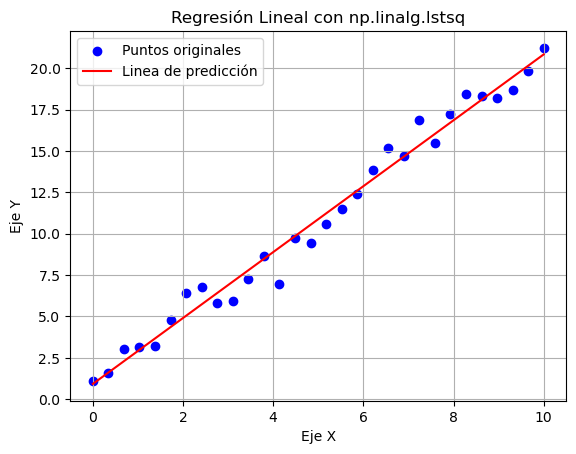

In [10]:
#Grafica
m, b = coef
y_pred = m * x + b

plt.figure()
plt.scatter(x,y,label="Puntos originales", color="b")
plt.plot(x,y_pred,label="Linea de predicción", color="r")
plt.xlabel('Eje X')
plt.ylabel('Eje Y')
plt.title('Regresión Lineal con np.linalg.lstsq')
plt.legend()
plt.grid()
plt.show()

In [11]:
#Acercamiento
ss_tot = np.sum((y - np.mean(y)) ** 2)
r2 = 1 - (residuos[0] / ss_tot)
print(f"R² (Calidad del ajuste): {r2:.4f}")

R² (Calidad del ajuste): 0.9818


In [12]:
#Conexión con proyección: Mínimos cuadrados proyecta y sobre el espacio generado por columnas de X.
residuo = y - X @ coef
print(X.T @ residuo) #Debe de ser cercano a [0,0]

[-7.44737605e-13 -1.20348176e-13]


**Conclusión:** Generé 30 puntos ruidosos de la recta y = 2x + 1 y construí la matriz de diseño X = [x, 1]. Con `np.linalg.lstsq` obtuve una pendiente de 1.99 y un intercepto de 0.93, muy cercanos a los valores reales (2 y 1), y coincidieron con `np.polyfit`. El ajuste tiene R² = 0.98. No salen exactos por el ruido y el número limitado de puntos. Mínimos cuadrados equivale a proyectar y sobre el espacio generado por las columnas de X, por eso el residuo queda perpendicular a ese espacio.

## Ejercicio 9: PCA desde cero

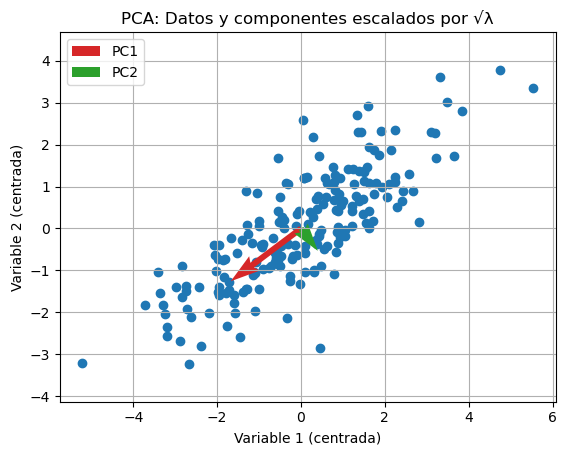

In [13]:
rng = np.random.default_rng(0)
datos = rng.multivariate_normal([0, 0], [[3, 2], [2, 2]], size=200)
#Centrar los datos
media = datos.mean(axis = 0)
datos_centrados = datos - media

#Matriz de covarianza
Matriz_covarianza = np.cov(datos_centrados.T)

#Valores y vectores propios
eigen_valores, eigen_vectores = np.linalg.eigh(Matriz_covarianza)

#Matrices simetricas y ordenados de mayor a menor
indices = np.argsort(eigen_valores)[::-1]
eigen_valores = eigen_valores[indices]
eigen_vectores = eigen_vectores[:,indices]

pc1 = eigen_vectores[:,0]
datos_proyectados_id = datos_centrados @ pc1

plt.figure()
plt.scatter(datos_centrados[:,0], datos_centrados[:,1])

colores = ["#d62728", "#2ca02c"]
for i in range(len(eigen_valores)):
    longitud = np.sqrt(eigen_valores[i])
    vector_escalado = eigen_vectores[:, i] * longitud
    plt.quiver(0, 0, vector_escalado[0], vector_escalado[1],
           angles='xy', scale_units='xy', scale=1,
           color=colores[i], width=0.012, label=f"PC{i+1}")
plt.xlabel("Variable 1 (centrada)")
plt.ylabel("Variable 2 (centrada)")
plt.title("PCA: Datos y componentes escalados por √λ")
plt.legend()
plt.grid()
plt.axis("equal")
plt.show()

In [14]:
varianza_explicada = eigen_valores / eigen_valores.sum()
for i in range(len(varianza_explicada)):
    print(f"PC{i+1} captura el {varianza_explicada[i]:1%} de la variación")

PC1 captura el 90.805544% de la variación
PC2 captura el 9.194456% de la variación


In [15]:
#Comparar con scikit-learn
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
pca.fit(datos) #Centrado
print(f"Varianza: {pca.explained_variance_}") #Eigenvalores
print(f"Componentes ->{pca.components_}")
print(f"Varianza = Eigenvalores -> {np.allclose(pca.explained_variance_, eigen_valores)}")

Varianza: [4.39819944 0.44533679]
Componentes ->[[ 0.79975026  0.60033284]
 [-0.60033284  0.79975026]]
Varianza = Eigenvalores -> True


In [16]:
U,s,Vt = np.linalg.svd(datos_centrados, full_matrices=False)
n = np.shape(datos_centrados)[0]
print(f"Varianza s**2/(n-1) -> {s**2/(n-1)}")
print(f"Filas son componentes principales [V transpuesta] -> {Vt}")


Varianza s**2/(n-1) -> [4.39819944 0.44533679]
Filas son componentes principales [V transpuesta] -> [[ 0.79975026  0.60033284]
 [-0.60033284  0.79975026]]


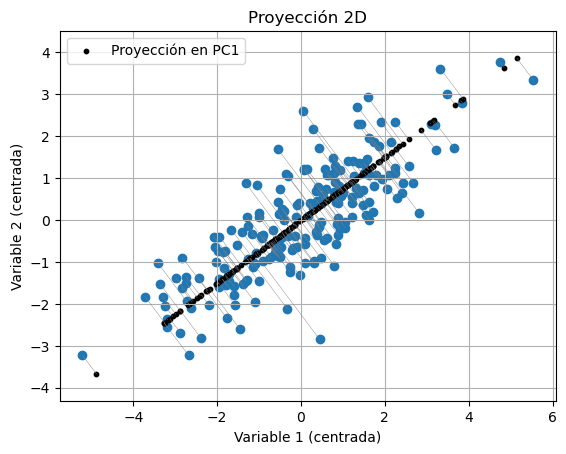

In [17]:
#Proyección PC1
proyeccion_2Dimensiones = np.outer(datos_proyectados_id, pc1) 
plt.figure()
plt.scatter(datos_centrados[:,0], datos_centrados[:,1])
plt.scatter(proyeccion_2Dimensiones[:, 0], proyeccion_2Dimensiones[:, 1], s=10, color="k", label="Proyección en PC1")
for original, proyectado in zip(datos_centrados, proyeccion_2Dimensiones):
    plt.plot([original[0], proyectado[0]], [original[1], proyectado[1]],
             color="gray", linewidth=0.3)
plt.title("Proyección 2D")
plt.xlabel("Variable 1 (centrada)")
plt.ylabel("Variable 2 (centrada)")
plt.legend()
plt.grid()
plt.axis("equal")
plt.show()

**Conclusión:** Generé 200 puntos 2D correlacionados, los centré y calculé la matriz de covarianza. Sus vectores propios (con `np.linalg.eigh`) son los componentes principales, y sus valores propios (4.40 y 0.45) son la varianza a lo largo de cada uno: PC1 captura el 90.8% de la variación y PC2 el 9.2%. Verifiqué que scikit-learn (`PCA`) y la SVD de los datos centrados (`s²/(n−1)`) dan los mismos valores y los mismos componentes, salvo el signo, que es arbitrario porque v y −v definen el mismo eje. Proyectar sobre PC1 reduce los datos de 2D a 1D conservando la mayor parte de la información.